<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session11_clustering_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱۱: خوشه‌بندی (Clustering)

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session11_clustering.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.datasets import make_moons, load_sample_image

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
mall = pd.read_csv(DATA_URL + "Mall_Customers.csv").rename(columns={
    "Genre": "Gender", "Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

بخش‌بندی مشتریان را با سه ویژگی `Age`، `Income` و `Spending` تکرار کنید. بهترین $K$ تغییر می‌کند؟ بخش‌های جدید را تفسیر کنید.

</div>

In [2]:
features = ["Age", "Income", "Spending"]
X3 = StandardScaler().fit_transform(mall[features])
scores = {k: silhouette_score(X3, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X3))
          for k in range(2, 11)}
print({k: round(v, 3) for k, v in scores.items()})
best_k = max(scores, key=scores.get)
print("Best k:", best_k)

mall["Segment3"] = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit_predict(X3)
mall.groupby("Segment3")[features].mean().round(1).assign(Count=mall["Segment3"].value_counts().sort_index())

{2: 0.335, 3: 0.358, 4: 0.404, 5: 0.417, 6: 0.428, 7: 0.417, 8: 0.408, 9: 0.418, 10: 0.407}
Best k: 6


,Age,Income,Spending,Count
Segment3,,,,
0,56.3,54.3,49.1,45
1,26.8,57.1,48.1,39
2,41.9,88.9,17.0,33
3,32.7,86.5,82.1,39
4,25.0,25.3,77.6,23
5,45.5,26.3,19.4,21


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با افزودن سن، بهترین $K$ (بر اساس Silhouette) تغییر می‌کند و مقدار Silhouette هم کمتر از حالت دوبعدی است؛ خوشه‌ها در سه بعد کمتر از هم جدا هستند. ولی بخش‌ها حالا معنای دقیق‌تری دارند: مثلاً گروه «خرید زیاد، درآمد کم» عمدتاً جوان است و گروه «درآمد زیاد، خرید کم» میانسال. جدول میانگین‌ها را برای نام‌گذاری هر بخش بخوانید. انتخاب نهایی $K$ باید هم به معیارها و هم به **قابل استفاده بودن** بخش‌ها برای تیم بازاریابی توجه کند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

نمودار Silhouette هر نمونه را برای $K=5$ رسم کنید (`silhouette_samples`). کدام خوشه ضعیف‌تر است؟

</div>

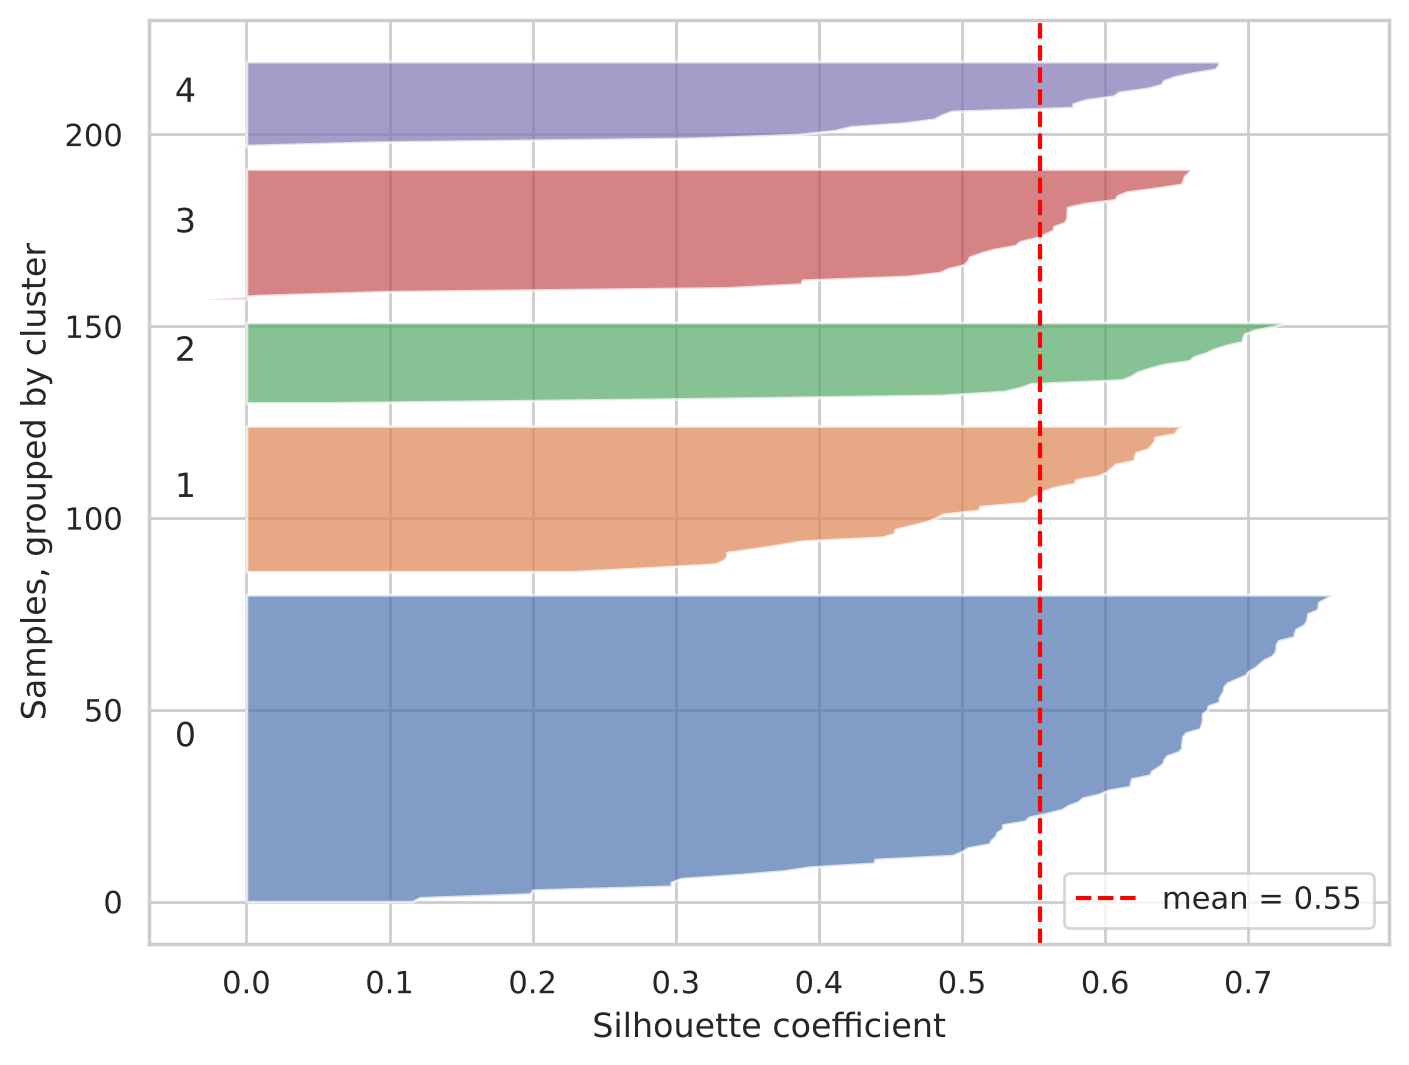

,income,spending,size,mean_silhouette
cluster,,,,
0,55.30,49.52,81,0.60
1,86.54,82.13,39,0.51
2,25.73,79.36,22,0.60
3,88.20,17.11,35,0.51
4,26.30,20.91,23,0.51


In [3]:
X2 = StandardScaler().fit_transform(mall[["Income", "Spending"]])
labels = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X2)
sil = silhouette_samples(X2, labels)

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 0
for k in range(5):
    vals = np.sort(sil[labels == k])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, alpha=0.7)
    ax.text(-0.05, y_lower + len(vals) / 2, str(k))
    y_lower += len(vals) + 5
ax.axvline(sil.mean(), color="red", linestyle="--", label=f"mean = {sil.mean():.2f}")
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Samples, grouped by cluster")
ax.legend()
plt.show()

pd.DataFrame({"Income": mall["Income"], "Spending": mall["Spending"], "silhouette": sil, "cluster": labels})\
  .groupby("cluster").agg(income=("Income", "mean"), spending=("Spending", "mean"),
                          size=("silhouette", "size"), mean_silhouette=("silhouette", "mean")).round(2)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

هر نوار یک نمونه است. همهٔ خوشه‌ها Silhouette بین ۰٫۵ و ۰٫۶ دارند و تقریباً هیچ نمونه‌ای مقدار منفی ندارد؛ خوشه‌بندی کلاً خوب است. ضعیف‌ترین خوشه‌ها (حدود ۰٫۵۱) سه گروه **درآمد زیاد** و گروه درآمد کم و خرید کم هستند: نمونه‌هایشان پراکنده‌ترند و بعضی‌شان به مرز خوشهٔ میانی نزدیک‌اند. جالب اینکه خوشهٔ بزرگ «درآمد متوسط، خرید متوسط» با وجود قرار گرفتن در وسط، بیشترین Silhouette را دارد، چون نمونه‌هایش بسیار فشرده‌اند. شهود ما دربارهٔ خوشهٔ «ضعیف» همیشه درست نیست؛ عدد را بررسی کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

`HDBSCAN` را روی `X_noisy` اجرا کنید و با DBSCAN مقایسه کنید.

</div>

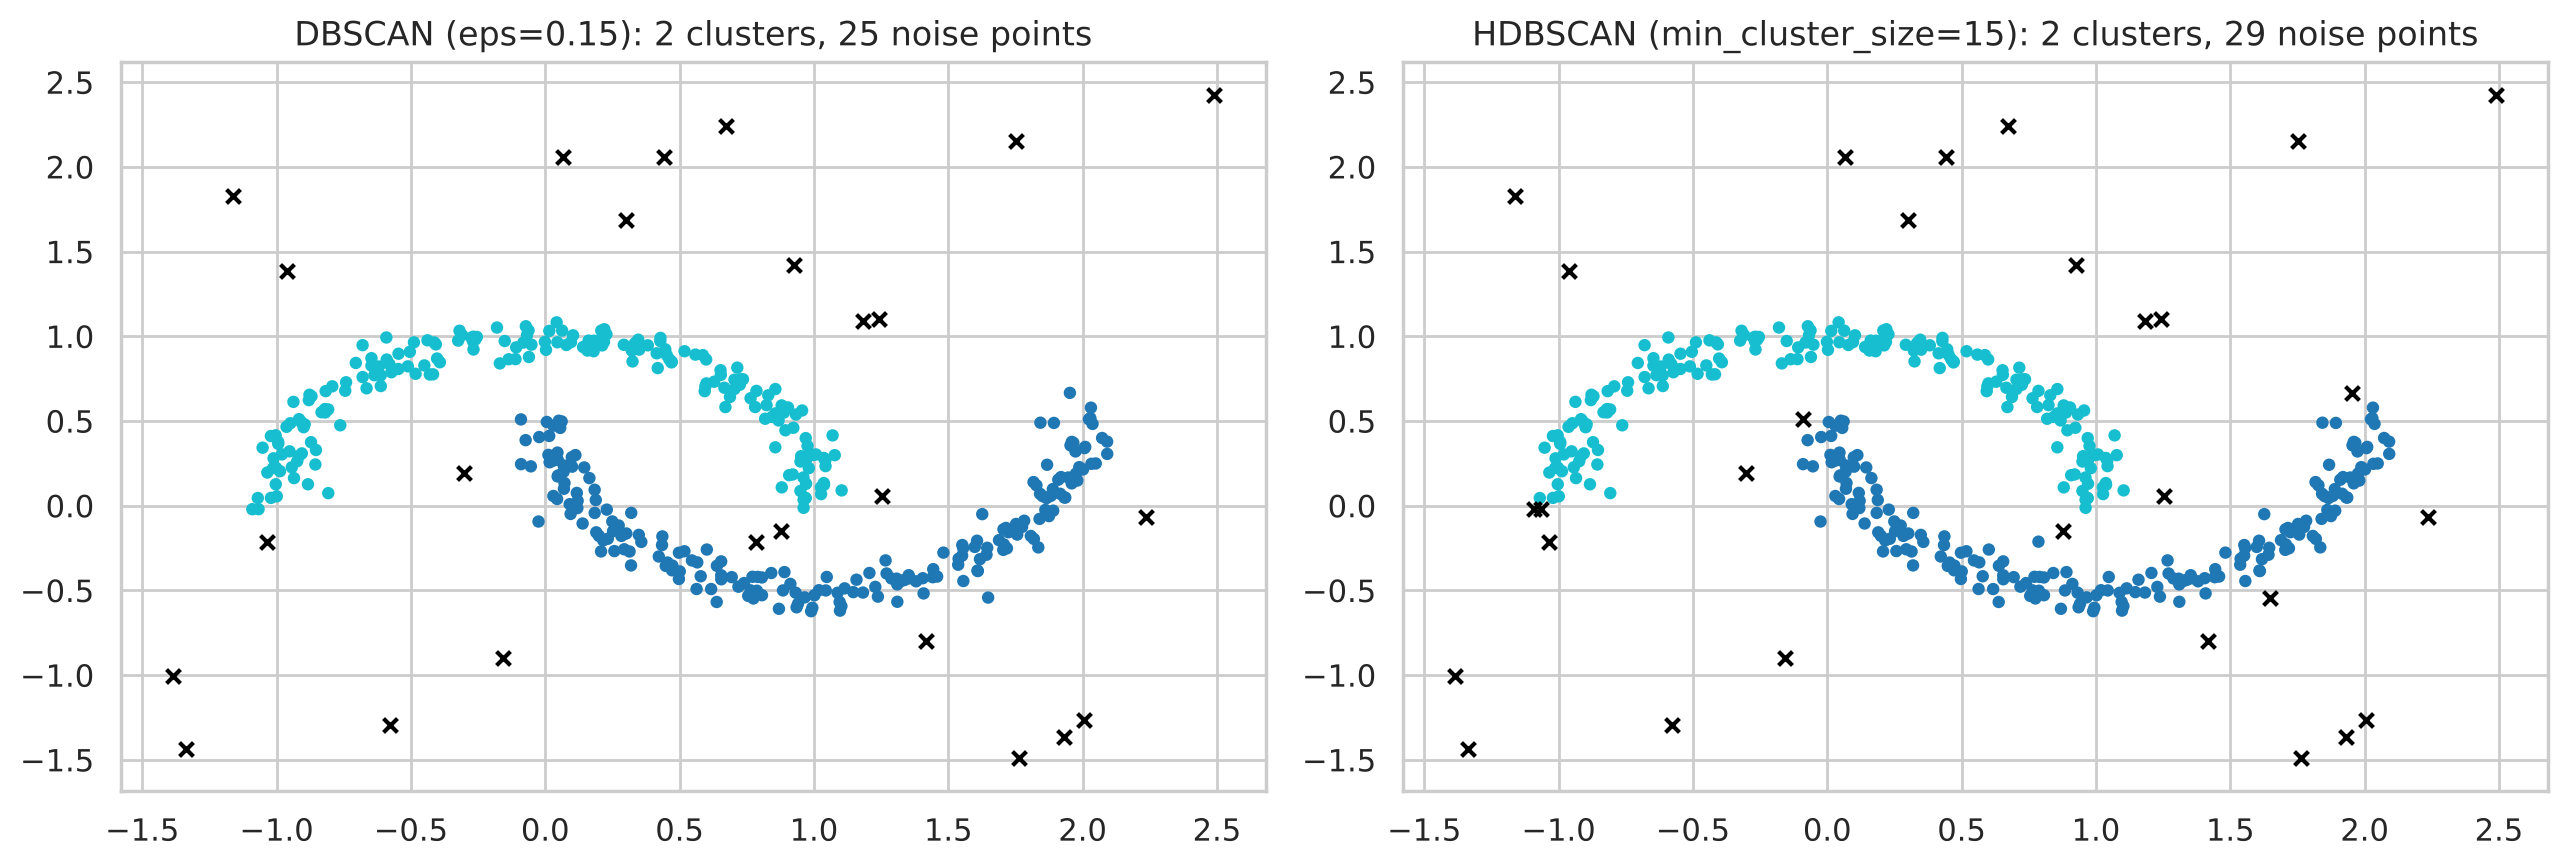

In [4]:
rng = np.random.default_rng(0)
X_moons, _ = make_moons(n_samples=400, noise=0.06, random_state=42)
X_noisy = np.vstack([X_moons, rng.uniform(-1.5, 2.5, (30, 2))])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, model) in zip(axes, [("DBSCAN (eps=0.15)", DBSCAN(eps=0.15, min_samples=5)),
                                    ("HDBSCAN (min_cluster_size=15)", HDBSCAN(min_cluster_size=15, copy=True))]):
    labels = model.fit_predict(X_noisy)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    ax.scatter(X_noisy[labels >= 0, 0], X_noisy[labels >= 0, 1], c=labels[labels >= 0], cmap="tab10", s=12)
    ax.scatter(X_noisy[labels == -1, 0], X_noisy[labels == -1, 1], c="black", marker="x", s=25)
    ax.set_title(f"{name}: {n_clusters} clusters, {np.sum(labels == -1)} noise points")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

HDBSCAN بدون نیاز به تنظیم `eps`، همان دو ماه را پیدا می‌کند و نقاط پراکنده را نویز تشخیص می‌دهد. تنها پارامتر اصلی آن `min_cluster_size` است که معنای ساده‌ای دارد: «کوچک‌ترین گروهی که برایم خوشه حساب می‌شود». مزیت اصلی HDBSCAN وقتی دیده می‌شود که خوشه‌ها **چگالی‌های متفاوت** دارند؛ جایی که هیچ `eps` واحدی برای DBSCAN مناسب نیست.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

**فشرده‌سازی تصویر:** تصویر رنگی `load_sample_image("china.jpg")` را بارگذاری کنید، پیکسل‌ها را با K-Means به ۸ رنگ خوشه‌بندی کنید و هر پیکسل را با رنگ مرکز خوشه‌اش جایگزین کنید.

</div>

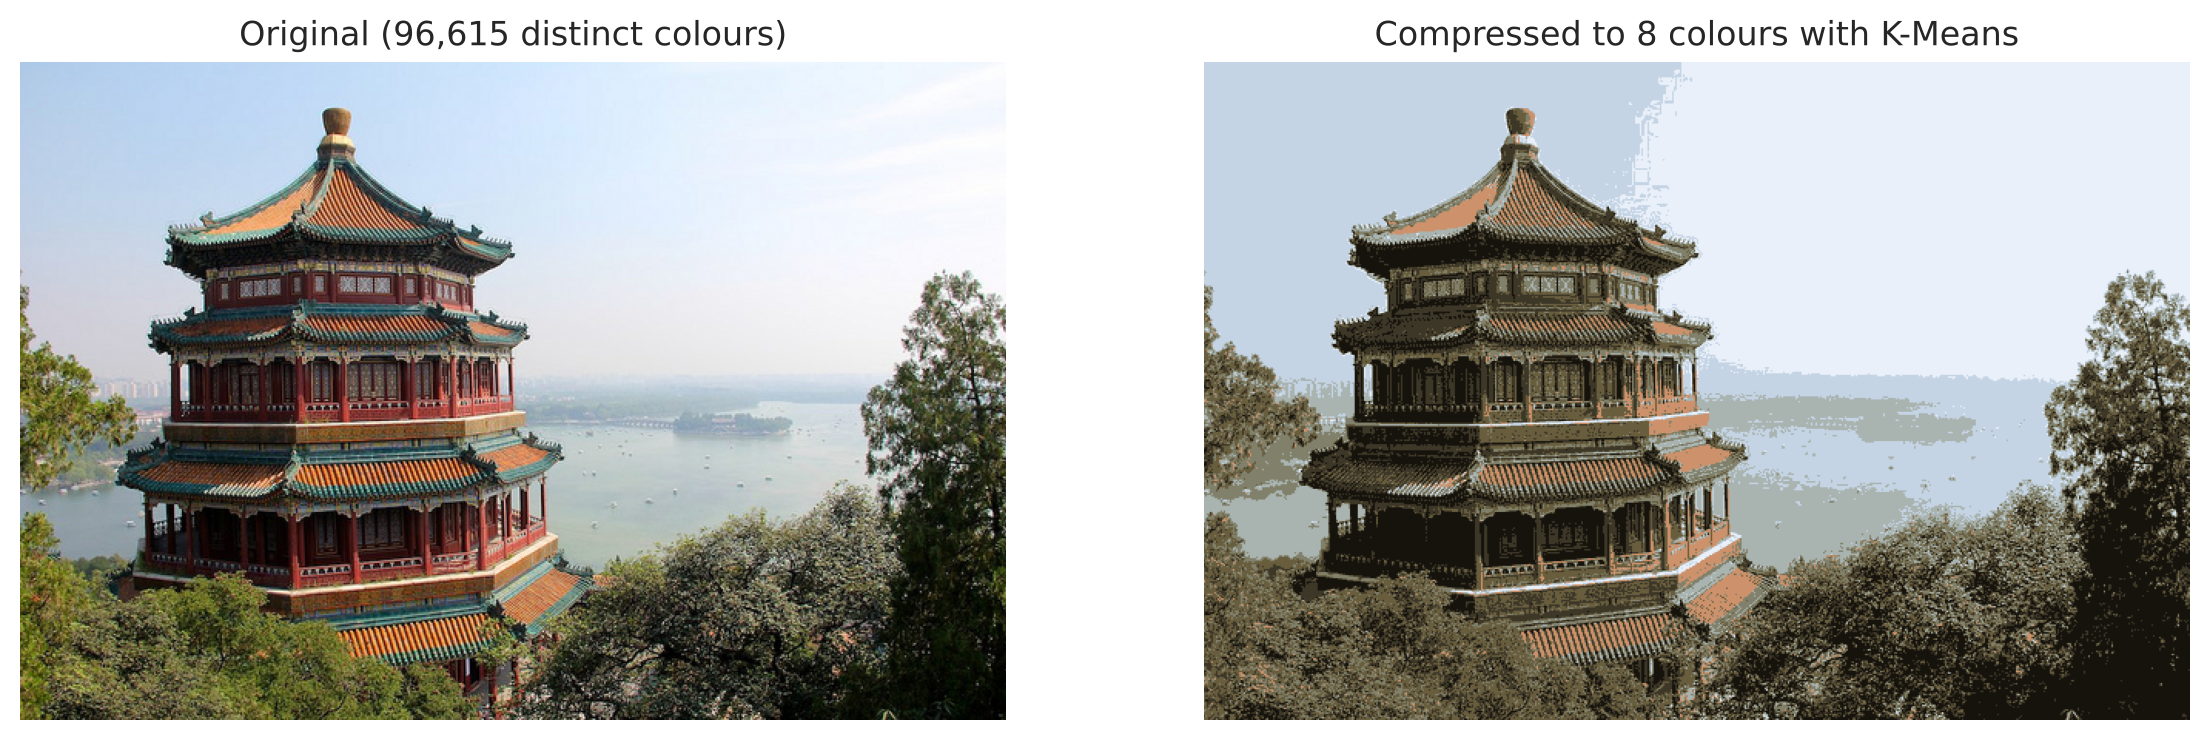

In [5]:
image = load_sample_image("china.jpg") / 255.0
pixels = image.reshape(-1, 3)
sample = pixels[np.random.default_rng(0).choice(len(pixels), 10_000, replace=False)]
kmeans = KMeans(n_clusters=8, n_init=4, random_state=42).fit(sample)       # fit on a sample for speed
compressed = kmeans.cluster_centers_[kmeans.predict(pixels)].reshape(image.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(image)
axes[0].set_title(f"Original ({len(np.unique(pixels, axis=0)):,} distinct colours)")
axes[1].imshow(compressed)
axes[1].set_title("Compressed to 8 colours with K-Means")
for ax in axes:
    ax.axis("off")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

تصویر اصلی ده‌ها هزار رنگ مختلف دارد؛ نسخهٔ فشرده فقط ۸ رنگ (مراکز خوشه‌ها). برای ذخیرهٔ تصویر فشرده، کافی است برای هر پیکسل فقط شمارهٔ خوشه (۳ بیت) و یک جدول ۸ رنگی نگه داریم؛ به‌جای ۲۴ بیت برای هر پیکسل، یعنی حدود ۸ برابر کوچک‌تر. برای سرعت، K-Means را روی نمونه‌ای ۱۰ هزار پیکسلی آموزش دادیم و سپس همهٔ پیکسل‌ها را با `predict` به نزدیک‌ترین مرکز نسبت دادیم.

</div>